# indiasim quick start

The Economy Lab model of the Indian economy, run from Python. It runs the same engine as the [website](https://slxnjdhv.github.io/india-economy-simulator/), calibrated to RBI, MoSPI and PLFS data for 2015–2024.

Install: `pip install indiasim`

In [1]:
import indiasim as isim
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.precision', 3)
isim.__version__

'0.1.0'

## 1. One economy: a failed monsoon

Each run first warms the economy up for 10 years. The monsoon then fails in month 4, and the RBI follows its usual rule. Rates are fractions, so 0.04 means 4%.

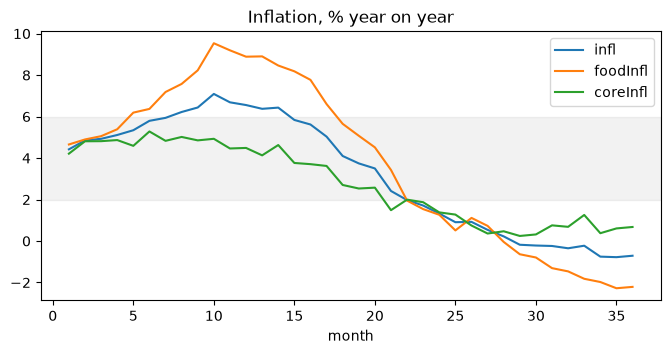

,infl,foodInfl,coreInfl,u,repo,inr_per_usd
month,,,,,,
1,0.044,0.047,0.042,0.046,0.068,83.602
7,0.059,0.072,0.048,0.071,0.083,85.542
13,0.064,0.089,0.041,0.099,0.090,84.693
25,0.009,0.005,0.013,0.117,0.060,85.979
36,-0.007,-0.022,0.007,0.086,0.035,85.089


In [2]:
df = isim.run(months=36, shocks=['monsoon'])
ax = (100 * df[['infl', 'foodInfl', 'coreInfl']]).plot(figsize=(8, 3.5), title='Inflation, % year on year')
ax.axhspan(2, 6, color='grey', alpha=0.1); ax.set_xlabel('month'); plt.show()
df[['infl', 'foodInfl', 'coreInfl', 'u', 'repo', 'inr_per_usd']].iloc[[0, 6, 12, 24, 35]]

## 2. The cost of lower inflation: a repo-rate sweep on 40 economies

Hold the repo rate between 1 point below and 2 points above its starting level for 3 years. Every setting uses the same 40 economies, so differences come from policy, not luck.

In [3]:
sw = isim.sweep('repoDelta', [-0.01, 0.0, 0.01, 0.02], seeds=range(1, 41), months=36)
yr23 = sw[sw.month > 12].groupby('repoDelta')[['infl', 'u']].mean() * 100
yr23.columns = ['inflation, %', 'unemployment, %']
yr23

,"inflation, %","unemployment, %"
repoDelta,,
-0.01,4.347,4.319
0.00,3.550,5.340
0.01,2.715,6.518
0.02,1.886,7.754


In [4]:
lo, hi = yr23.iloc[0], yr23.iloc[-1]
ratio = (hi['unemployment, %'] - lo['unemployment, %']) / (lo['inflation, %'] - hi['inflation, %'])
print(f'Sacrifice ratio: {ratio:.2f} points of unemployment per point of inflation')

Sacrifice ratio: 1.40 points of unemployment per point of inflation


## 3. Oil, the rupee and imported inflation

World oil prices double in month 3. Compare 40 economies with and without the shock.

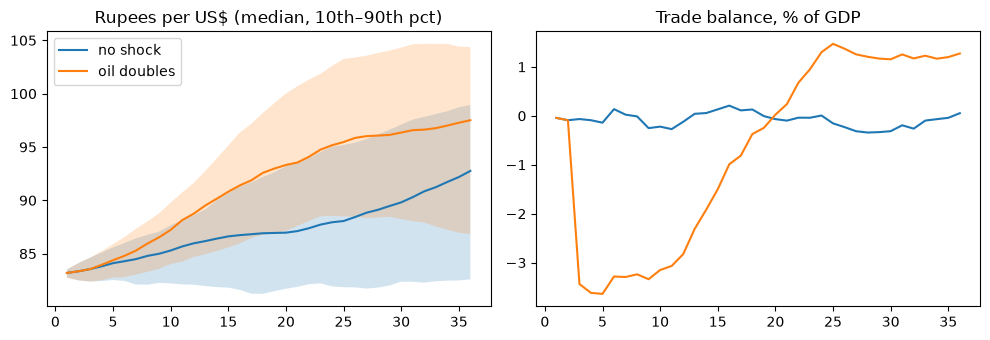

In [5]:
none = isim.run_many(seeds=range(1, 41), months=36, policy='fixed')
oil = isim.run_many(seeds=range(1, 41), months=36, policy='fixed', shocks=[{'key': 'oil', 'start': 2, 'depth': 1.0}])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for name, d in [('no shock', none), ('oil doubles', oil)]:
    q = d.groupby('month')['inr_per_usd'].quantile([0.1, 0.5, 0.9]).unstack()
    ax[0].plot(q.index, q[0.5], label=name); ax[0].fill_between(q.index, q[0.1], q[0.9], alpha=0.2)
    ax[1].plot(d.groupby('month')['tradeBal'].mean() * 100, label=name)
ax[0].set_title('Rupees per US$ (median, 10th–90th pct)'); ax[1].set_title('Trade balance, % of GDP')
ax[0].legend(); plt.tight_layout(); plt.show()

## 4. Does a large informal sector weaken monetary policy?

Informal firms borrow from moneylenders, whose rates don't follow the repo rate. For each informal-sector size, compare a 2-point rate hike with no change, on the same 20 economies.

In [6]:
rows = []
for inf in [0.2, 0.5, 0.75, 1.0]:
    p = {'informal': inf}
    base = isim.run_many(seeds=range(1, 21), months=24, policy='fixed', params=p)
    hike = isim.run_many(seeds=range(1, 21), months=24, policy={'repoDelta': 0.02}, params=p)
    y2 = lambda d, k: d[d.month > 12][k].mean() * 100
    rows.append({'informal setting': inf, 'informal share of jobs, %': y2(base, 'infShare'),
                 'fall in inflation, pts': y2(base, 'infl') - y2(hike, 'infl'),
                 'rise in unemployment, pts': y2(hike, 'u') - y2(base, 'u')})
pd.DataFrame(rows).set_index('informal setting')

,"informal share of jobs, %","fall in inflation, pts","rise in unemployment, pts"
informal setting,,,
0.20,32.098,1.612,2.360
0.50,66.245,1.555,2.361
0.75,80.623,1.482,2.232
1.00,90.072,1.414,2.280


## 5. Step by step, like a policymaker

In [7]:
e = isim.Economy(seed=74).warm_up(rule=False)   # repo held where the warm-up left it
e.run(6)
e.shock('monsoon')
e.run(4)
e.set(repo=0.075)                               # respond with a hike
e.run(14)
e.history.loc[1:, ['repo', 'infl', 'foodInfl', 'u']].iloc[::4]

,repo,infl,foodInfl,u
month,,,,
1,0.062,0.044,0.047,0.046
5,0.062,0.047,0.047,0.041
9,0.062,0.060,0.069,0.045
13,0.075,0.065,0.084,0.070
17,0.075,0.066,0.091,0.081
21,0.075,0.046,0.064,0.091


## 6. How well does the model match India?

The calibration statistics, 2015–2024: the Indian value, the model average over 10 economies of 20 years, and the model's 10th–90th percentile range.

In [8]:
isim.moments()

,india,model,model_p10,model_p90,targeted,gap_in_scales
inflMean,0.050,3.848e-02,0.033,0.043,True,-2.286
inflSd,0.011,1.333e-02,0.010,0.017,True,0.509
foodSd,0.026,2.035e-02,0.017,0.026,True,-0.699
coreSd,0.009,1.078e-02,0.007,0.014,False,0.376
inflAc1,0.231,1.036e-01,-0.144,0.319,True,-0.848
uMean,0.045,4.445e-02,0.038,0.054,True,-0.053
repoMean,0.058,6.085e-02,0.046,0.090,True,0.681
repoSd,0.011,1.587e-02,0.009,0.020,False,1.314
erChgMean,0.032,3.332e-02,0.028,0.039,True,0.173
erChgSd,0.030,2.870e-02,0.024,0.034,True,-0.149


## 7. Reproducibility

The same settings and economy number always give the same result, in Python and on the website. The fingerprint identifies a run exactly.

In [9]:
a = isim.run(months=36, seed=74, shocks=['monsoon'])
b = isim.run(months=36, seed=74, shocks=['monsoon'])
a.attrs['fingerprint'], a.attrs['fingerprint'] == b.attrs['fingerprint'], a.attrs['balanced']

('d1fdf765', True, True)